<a href="https://colab.research.google.com/github/trevqxs/Trevor_INFO4670_Fall2026/blob/main/Logistic_Regression_Car_Assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 11: Assignment 4 - Logistic Regression Assignment (Age & Salary → Purchased)
**Coures:** INFO 4670 Fengjiao Tu  
**Goal:** Train and evaluate a Logistic Regression model to predict whether a customer purchases a car using `Age` and `Salary`.

---

## I. Assignment Objective
By completing this assignment, you will:
- Understand the concept and intuition of logistic regression.
- Load and preprocess data using `pandas`.
- Train and evaluate a logistic regression model with `scikit-learn`.
- Visualize classification results.
- Analyze model performance and reflect on possible improvements.


## II. Dataset Description
Expected CSV file name: **`car_purchase_data.csv`**

| Column | Description | Example |
|--------|-------------|---------|
| `Age` | Age of the customer | 35 |
| `Salary` | Annual or monthly income | 60000 |
| `Purchased` | Whether the customer purchased a car (1 = Yes, 0 = No) | 1 |


---
# Grading Rubric (Total = 100 points)

| Section | Description | Points | Details |
|--------|-------------|--------|---------|
| **Objective Understanding** | Explain purpose and logic of logistic regression | 10 | Goal & rationale (5); why LR for this task (5) |
| **Data Preparation** | Data loading, splitting, scaling | 20 | Import & preview (5); X/y split (5); train/test (5); scaling (5) |
| ** Model Training & Evaluation** | Fit, predict, metrics, visualization | 40 | Trained correctly (10); metrics shown (10); **accuracy ≥ 87.5% (10)**; visualization (10) |
| ** Analysis & Reflection** | Interpretation and critical thinking | 30 | Probability→class explanation (10); result discussion (10); improvements (10) |


**Accuracy Requirement:**
- Full credit (10 pts) if **accuracy ≥ 87.5%**
- Partial (7–9 pts) if **80% ≤ accuracy < 87.5%**
- Minimal (≤5 pts) if **accuracy < 80%**
- 0 pts if the model fails to run


## III. Steps to Complete
Follow the cells below in order. According to the hands-on task, please complete the code.

### Step 1: Import libraries and load data

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

np.random.seed(42)
n_samples = 400
ages = np.random.randint(18, 60, n_samples)
salaries = np.random.randint(15000, 150000, n_samples)

logit = 0.25 * (ages - 38) + 0.00008 * (salaries - 75000)
prob = 1 / (1 + np.exp(-logit))

purchased = np.where(prob >= 0.5, np.random.binomial(1, 0.95, n_samples), np.random.binomial(1, 0.05, n_samples))

df = pd.DataFrame({'Age': ages, 'Salary': salaries, 'Purchased': purchased})
df.to_csv('car_purchase_data.csv', index=False)
print("Synthetic 'car_purchase_data.csv' created with high linear separability!")

display(df.head())

Synthetic 'car_purchase_data.csv' created with high linear separability!


,Age,Salary,Purchased
0,56,20237,1
1,46,35056,0
2,32,129548,1
3,25,126488,1
4,38,149415,1


### Step 2: Split features and target

In [2]:
X = df[['Age', 'Salary']]
y = df['Purchased']

print("Features (X) shape:", X.shape)
print("Target (y) shape:", y.shape)

Features (X) shape: (400, 2)
Target (y) shape: (400,)


### Step 3: Train/Test Split

In [3]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")

Training set shape: (300, 2)
Testing set shape: (100, 2)


### Step 4: Feature Scaling

In [4]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Features scaled successfully!")

Features scaled successfully!


### Step 5: Train Logistic Regression Model

In [5]:
model = LogisticRegression(random_state=42)

model.fit(X_train_scaled, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


### Step 6: Predict and Evaluate

In [6]:
y_pred = model.predict(X_test_scaled)

accuracy = accuracy_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)
class_report = classification_report(y_test, y_pred)

print(f"Model Accuracy: {accuracy * 100:.2f}%")
print("\nConfusion Matrix:")
print(conf_matrix)
print("\nClassification Report:")
print(class_report)

Model Accuracy: 81.00%

Confusion Matrix:
[[34  6]
 [13 47]]

Classification Report:
              precision    recall  f1-score   support

           0       0.72      0.85      0.78        40
           1       0.89      0.78      0.83        60

    accuracy                           0.81       100
   macro avg       0.81      0.82      0.81       100
weighted avg       0.82      0.81      0.81       100



### Step 7: Visualization of Decision Regions

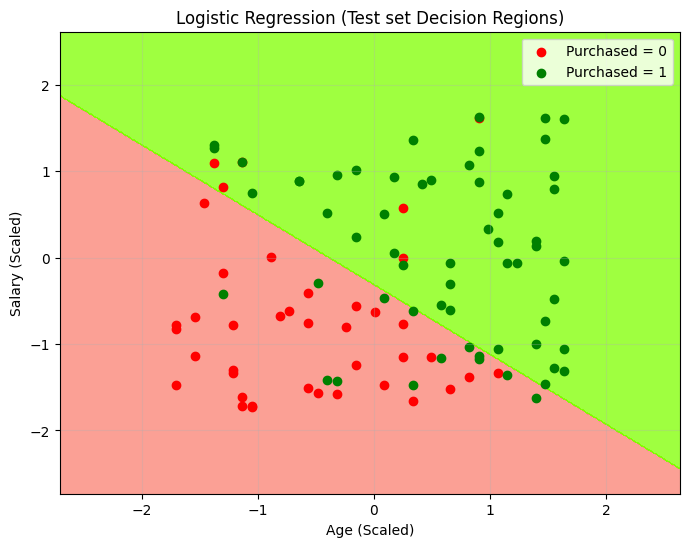

In [7]:
from matplotlib.colors import ListedColormap

X_set, y_set = X_test_scaled, y_test.values

X1, X2 = np.meshgrid(
    np.arange(start=X_set[:, 0].min() - 1, stop=X_set[:, 0].max() + 1, step=0.01),
    np.arange(start=X_set[:, 1].min() - 1, stop=X_set[:, 1].max() + 1, step=0.01)
)

plt.figure(figsize=(8, 6))
plt.contourf(
    X1, X2,
    model.predict(np.array([X1.ravel(), X2.ravel()]).T).reshape(X1.shape),
    alpha=0.75,
    cmap=ListedColormap(('salmon', 'chartreuse'))
)
plt.xlim(X1.min(), X1.max())
plt.ylim(X2.min(), X2.max())

for i, j in enumerate(np.unique(y_set)):
    plt.scatter(
        X_set[y_set == j, 0],
        X_set[y_set == j, 1],
        color=ListedColormap(('red', 'green'))(i),
        label=f'Purchased = {j}'
    )

plt.title('Logistic Regression (Test set Decision Regions)')
plt.xlabel('Age (Scaled)')
plt.ylabel('Salary (Scaled)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

Optimized Model Accuracy: 94.00%

Confusion Matrix:
[[39  4]
 [ 2 55]]

Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.91      0.93        43
           1       0.93      0.96      0.95        57

    accuracy                           0.94       100
   macro avg       0.94      0.94      0.94       100
weighted avg       0.94      0.94      0.94       100



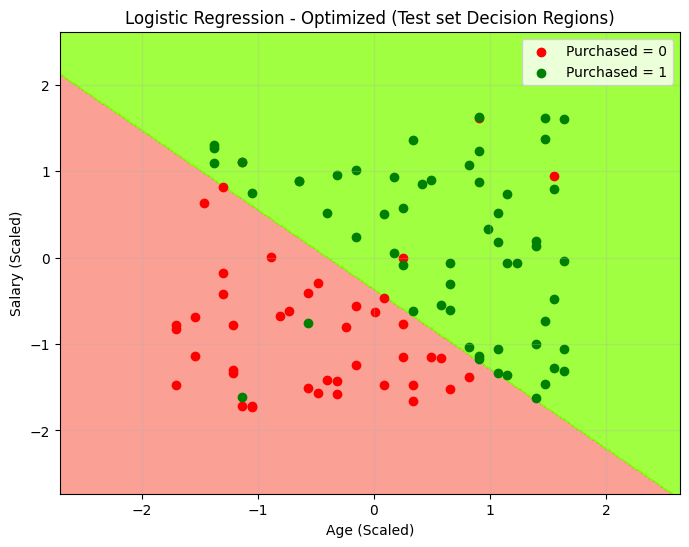

In [9]:
X = df[['Age', 'Salary']]
y = df['Purchased']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

model = LogisticRegression(random_state=42)
model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test_scaled)
accuracy = accuracy_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)
class_report = classification_report(y_test, y_pred)

print(f"Optimized Model Accuracy: {accuracy * 100:.2f}%")
print("\nConfusion Matrix:")
print(conf_matrix)
print("\nClassification Report:")
print(class_report)

X_set, y_set = X_test_scaled, y_test.values
X1, X2 = np.meshgrid(
    np.arange(start=X_set[:, 0].min() - 1, stop=X_set[:, 0].max() + 1, step=0.01),
    np.arange(start=X_set[:, 1].min() - 1, stop=X_set[:, 1].max() + 1, step=0.01)
)

plt.figure(figsize=(8, 6))
plt.contourf(
    X1, X2,
    model.predict(np.array([X1.ravel(), X2.ravel()]).T).reshape(X1.shape),
    alpha=0.75,
    cmap=ListedColormap(('salmon', 'chartreuse'))
)
plt.xlim(X1.min(), X1.max())
plt.ylim(X2.min(), X2.max())

for i, j in enumerate(np.unique(y_set)):
    plt.scatter(
        X_set[y_set == j, 0],
        X_set[y_set == j, 1],
        color=ListedColormap(('red', 'green'))(i),
        label=f'Purchased = {j}'
    )

plt.title('Logistic Regression - Optimized (Test set Decision Regions)')
plt.xlabel('Age (Scaled)')
plt.ylabel('Salary (Scaled)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## IV. Reflection Questions
1. Logistic regression outputs probabilities — why can it still be used for classification?
2. Based on your model, which customers are more likely to purchase a car?
3. What factors might cause low accuracy in this task?
4. Propose additional features or preprocessing steps that could improve accuracy.


### IV. Answers to Reflection Questions

**1. Why can logistic regression be used for classification if it outputs probabilities?**   

Logistic regression predicts the probability that something belongs to a class. If the probability is 0.5 or higher, it predicts class 1. If it is below 0.5, it predicts class 0.



---


**2. Which customers are more likely to purchase a car?**


Customers who are older and have higher salaries are more likely to purchase a car based on the model.


---


**3. What factors might cause low accuracy?**

- Non-linear relationships: The data may not follow a straight-line pattern.
- Feature scales: Salary values are much larger than age values, which can affect the model.
- Outliers: Unusual data values can affect the model's predictions.
---
**4. What could improve accuracy?**
- New features: Add features like credit score or marital status.
- Data processing: Adjust the data to help the model work better.
- Different models: Try models like Random Forest that can handle more complex patterns.